In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import cross_validate
from sklearn.metrics import RocCurveDisplay
import kds

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.multiclass import OneVsRestClassifier
import sys
import utils

# Academic Outcome Classification

**Research question.** Can a group of academic indicators and learning-related measures help distinguish between students who pass and those who fail their first year of college?

This notebook uses **1,131 records** and a binary outcome column, `Pass` (`Pass` or `Fail`). The explanatory variables capture several dimensions:

| Dimension | Variables included |
| --- | --- |
| Prior attainment | `Maths`, `English`, `CAO Points` |
| Learning preferences | `Auditory`, `Kinaesthetic`, `Visual` |
| Motivation and habits | `Extrinsic Motivation`, `Intrinsic Motivation`, `Study Time` |
| Personal attributes | `Self-Efficacy`, `Conscientiousness`, `age` |

The goal is to compare classification approaches and examine how reliably they separate the two outcome classes. The target is categorical; the predictor fields are numerical. Dataset completeness is checked below before fitting any models.


In [2]:
# Read the semicolon-delimited academic records
student = pd.read_csv('data/academic_profiles.csv', sep=';')

# Inspect a small sample of observations
student.head()


,age,Auditory,Kinaesthetic,Visual,Extrinsic Motivation,Intrinsic Motivation,Self-Efficacy,Study Time,Conscientiousness,CAO Points,Maths,English,Pass
0,19,5.000000,6.698392,3.301608,9.308199,6.875000,7.321865,7.790997,8.721329,352.0,19.0,45.0,Pass
1,31,6.285538,2.500000,6.214462,7.535538,6.303307,7.095179,6.892769,6.440564,187.0,35.0,28.0,Pass
2,36,6.776966,2.500000,5.723034,8.026966,7.040449,7.258989,7.138483,6.194850,111.0,21.0,17.0,Pass
3,22,6.756132,3.987737,4.256132,6.621934,5.945164,5.089465,2.500000,4.042689,327.0,36.0,46.0,Fail
4,23,7.228655,2.228655,5.542690,6.453509,6.942836,6.285575,3.314034,4.528460,274.0,33.0,35.0,Fail


In [3]:
student.info()

<class 'pandas.DataFrame'>
RangeIndex: 1131 entries, 0 to 1130
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1131 non-null   int64  
 1   Auditory              1131 non-null   float64
 2   Kinaesthetic          1131 non-null   float64
 3   Visual                1131 non-null   float64
 4   Extrinsic Motivation  1131 non-null   float64
 5   Intrinsic Motivation  1131 non-null   float64
 6   Self-Efficacy         1131 non-null   float64
 7   Study Time            1131 non-null   float64
 8   Conscientiousness     1131 non-null   float64
 9   CAO Points            1131 non-null   float64
 10  Maths                 1131 non-null   float64
 11  English               1131 non-null   float64
 12  Pass                  1131 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 115.0 KB


## Data integrity: identifying incomplete entries

Before constructing model inputs, inspect the available observations and apply the notebook's existing missing-value treatment.


In [4]:
# Impute text fields using their most frequent entry
student = student.copy()
for col in student.select_dtypes(include=['object']).columns:
    student[col] = student[col].fillna(student[col].mode()[0])

# Replace empty numeric entries with the column average
for col in student.select_dtypes(include=['float64', 'int64']).columns:
    student[col] = student[col].fillna(student[col].mean())
# Report any null values remaining after this pass
print("\nMissing values after handling:")
print(student.isnull().sum())

# Show a short sample of the prepared data
print("\nPreview of updated dataset:")
print(student.head())



Missing values after handling:
age                     0
Auditory                0
Kinaesthetic            0
Visual                  0
Extrinsic Motivation    0
Intrinsic Motivation    0
Self-Efficacy           0
Study Time              0
Conscientiousness       0
CAO Points              0
Maths                   0
English                 0
Pass                    0
dtype: int64

Preview of updated dataset:
   age  Auditory  Kinaesthetic    Visual  Extrinsic Motivation  \
0   19  5.000000      6.698392  3.301608              9.308199   
1   31  6.285538      2.500000  6.214462              7.535538   
2   36  6.776966      2.500000  5.723034              8.026966   
3   22  6.756132      3.987737  4.256132              6.621934   
4   23  7.228655      2.228655  5.542690              6.453509   

   Intrinsic Motivation  Self-Efficacy  Study Time  Conscientiousness  \
0              6.875000       7.321865    7.790997           8.721329   
1              6.303307       7.095179    6.8

### Preparation checkpoint

The preceding cell fills missing entries, if present, with the most common categorical value or the numerical mean. The next stage reloads the source file to produce an encoded copy for feature preparation. This preserves the sequence of the original analysis.


## Representing class labels numerically

Convert the pass/fail outcome to an encoded target. Any other categorical predictors are handled through indicator columns.


In [5]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Reopen the input table for the encoding stage
student = pd.read_csv('data/academic_profiles.csv', sep=';')

# Work on a separate table to retain the original observations
student_encoded = student.copy()

# Convert the two-class outcome into numeric codes
le = LabelEncoder()
student_encoded['Pass'] = le.fit_transform(student_encoded['Pass'])  # Encoding: successful outcomes map to 1; unsuccessful to 0

# Identify any remaining columns containing text
categorical_cols = student_encoded.select_dtypes(include=['object']).columns

# Expand other categorical fields into binary indicators
student_encoded = pd.get_dummies(student_encoded, columns=categorical_cols, drop_first=True)

# Inspect the numerical representation
print("Encoded dataset preview:")
print(student_encoded.head())


Encoded dataset preview:
   age  Auditory  Kinaesthetic    Visual  Extrinsic Motivation  \
0   19  5.000000      6.698392  3.301608              9.308199   
1   31  6.285538      2.500000  6.214462              7.535538   
2   36  6.776966      2.500000  5.723034              8.026966   
3   22  6.756132      3.987737  4.256132              6.621934   
4   23  7.228655      2.228655  5.542690              6.453509   

   Intrinsic Motivation  Self-Efficacy  Study Time  Conscientiousness  \
0              6.875000       7.321865    7.790997           8.721329   
1              6.303307       7.095179    6.892769           6.440564   
2              7.040449       7.258989    7.138483           6.194850   
3              5.945164       5.089465    2.500000           4.042689   
4              6.942836       6.285575    3.314034           4.528460   

   CAO Points  Maths  English  Pass  
0       352.0   19.0     45.0     1  
1       187.0   35.0     28.0     1  
2       111.0   21.0     

### Encoded feature set

`LabelEncoder` assigns a numerical representation to `Pass` (`Fail` → `0`, `Pass` → `1`). The transformed table provides a numerical view of the available variables; the following cell creates a separately scaled version.


## Feature scaling

Standardization produces a mean-centred, variance-scaled representation of the predictors. The outcome column is appended unchanged.


In [6]:
from sklearn.preprocessing import StandardScaler

# Create a standardization transformer
scaler = StandardScaler()

# Normalize predictor variables, excluding the outcome
student_encoded_scaled = scaler.fit_transform(student_encoded.drop(columns=['Pass']))

# Rebuild a labelled table from the transformed features
student_encoded_scaled = pd.DataFrame(student_encoded_scaled, columns=student_encoded.drop(columns=['Pass']).columns)
student_encoded_scaled['Pass'] = student_encoded['Pass']


## Hold-out assessment: decision tree

Create a stratified training/test partition and evaluate a baseline decision-tree classifier. The split and model settings are retained from the original notebook.


In [7]:



# Identify predictors and outcome labels
X = student.drop('Pass', axis=1)
y = student['Pass']

# Reserve a stratified subset for evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    stratify=y, 
    random_state=43
)

# Display the dimensions of both partitions
print(len(X_train), len(y_train))  # Number of training observations
print(len(X_test), len(y_test))    # Number of test observations

# Configure the baseline tree
dt_clf = DecisionTreeClassifier(random_state=43)

# Fit the tree on the training partition
dt_clf.fit(X_train, y_train)

# Generate predictions for the test partition
predictions = dt_clf.predict(X_test)

# Report the proportion of correctly classified examples
print("Accuracy:", accuracy_score(y_test, predictions))


791 791
340 340
Accuracy: 0.75


### Reading the initial score

The training and test counts printed above reflect the 70/30 partition. The accuracy value provides an initial measure of how well the tree predicts held-out outcomes. A single split is not a complete measure of generalization, so the subsequent confusion matrix and cross-validation checks offer additional context. If accuracy appears unusually high, check for overfitting or data leakage before drawing conclusions.


In [8]:
# Bring in the confusion-matrix utility
from sklearn.metrics import confusion_matrix

# Compute counts for each actual/predicted class pair
confusion_m = confusion_matrix(y_test, predictions)

# Show the resulting contingency table
print("Confusion Matrix:")
print(confusion_m)


Confusion Matrix:
[[ 83  43]
 [ 42 172]]


### Interpreting prediction errors

The confusion matrix separates correct classifications from false positives and false negatives. Inspect errors for both `Fail` and `Pass` rather than relying exclusively on total accuracy. Their relative frequencies indicate where the classifier needs further assessment.


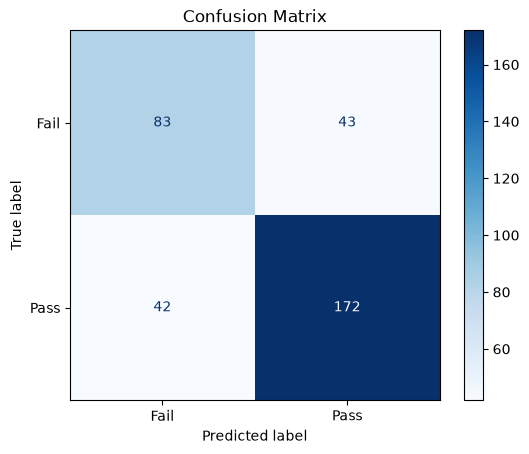

In [9]:
# Import tools for matrix visualization
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Recalculate class-level error counts
confusion_m = confusion_matrix(y_test, predictions)

# Render a labelled confusion-matrix chart
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_m, display_labels=["Fail", "Pass"])
disp.plot(cmap=plt.cm.Blues)

# Draw the figure
plt.title('Confusion Matrix')
plt.show()


In [10]:
# Summarize precision, recall, and F1 by outcome
print(classification_report(y_test, predictions))


              precision    recall  f1-score   support

        Fail       0.66      0.66      0.66       126
        Pass       0.80      0.80      0.80       214

    accuracy                           0.75       340
   macro avg       0.73      0.73      0.73       340
weighted avg       0.75      0.75      0.75       340



### Beyond overall accuracy

Precision, recall, and F1-score help describe the behavior of the classifier for each outcome. In the original interpretation, the `Pass` class was handled more effectively than `Fail`. Review the newly printed report to determine whether the difference persists in your environment.


A useful next objective is to improve detection of unsuccessful outcomes while maintaining reasonable precision. Class-level metrics are more informative than a single aggregate score for this purpose.


**Decision-tree review**

- Evaluate performance for `Fail` and `Pass` separately, especially recall for `Fail`.
- Use the weighted and macro averages to understand the gap between overall and per-class behavior.
- Compare the hold-out evaluation with cross-validation before selecting a model.


In [11]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import f1_score, roc_auc_score, classification_report
from scipy.stats import loguniform
import numpy as np

# Partition the available examples
X = student.drop('Pass', axis=1)
y = student['Pass']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Configure an RBF-kernel support vector classifier
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True)

# Estimate the model from the training records
svm_model.fit(X_train, y_train)

# Predict outcomes for the held-out records
predictions = svm_model.predict(X_test)

# Report the selected evaluation measures
print("F1-Score:", f1_score(y_test, predictions, pos_label='Pass'))
print("AUC:", roc_auc_score(y_test, svm_model.predict_proba(X_test)[:, 1]))
print(classification_report(y_test, predictions))

# Explore alternative settings with a randomized search
# Limit the search to ten sampled configurations
param_distributions = {
    'C': loguniform(1e-1, 1e1),      # Candidate regularization interval
    'kernel': ['linear', 'rbf'],         # Kernel options under consideration
    'gamma': ['scale', 'auto']           # Gamma settings to compare
}

# Allow parallel execution across available workers
# Evaluate ten sampled hyperparameter combinations
random_search = RandomizedSearchCV(
    SVC(probability=True, random_state=42), 
    param_distributions=param_distributions, 
    n_iter=10, 
    cv=5, 
    scoring='f1', 
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best parameters:", random_search.best_params_)
print("Best F1 Score:", random_search.best_score_)

F1-Score: 0.7725631768953068
AUC: 0.6885847797062751
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00       126
        Pass       0.63      1.00      0.77       214

    accuracy                           0.63       340
   macro avg       0.31      0.50      0.39       340
weighted avg       0.40      0.63      0.49       340

Best parameters: {'C': np.float64(0.5611516415334505), 'gamma': 'scale', 'kernel': 'linear'}
Best F1 Score: nan


## Alternative classifiers: support vectors and neighbours

The available predictors describe achievement, study patterns, and self-reported learning attributes. **Support vector machines (SVMs)** build a separating boundary in feature space, whereas **k-nearest neighbours (k-NN)** uses similarity among observations. The following experiments compare these complementary approaches.


## Support vector machine: initial fit


In [12]:
from sklearn.svm import SVC

# Construct the support vector estimator
svm_clf = SVC(kernel='rbf', random_state=42)

# Fit its parameters to the training examples
svm_clf.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


### Performance diagnostics

Generate predictions for the held-out records and review the classification report alongside the confusion matrix.


In [14]:
from sklearn.svm import SVC

# Set up the evaluation-time SVM
svc_model = SVC(random_state=42)

# Fit the classifier with the existing training split
svc_model.fit(X_train, y_train)

# Estimate labels for the evaluation subset
predictions = svc_model.predict(X_test)


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print(classification_report(y_test, predictions))
print(confusion_matrix(y_test, predictions))


              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00       126
        Pass       0.63      1.00      0.77       214

    accuracy                           0.63       340
   macro avg       0.31      0.50      0.39       340
weighted avg       0.40      0.63      0.49       340

[[  0 126]
 [  0 214]]


### What the SVM errors suggest

The original evaluation reported weak identification of the `Fail` class relative to `Pass`. Such a pattern can arise when the boundary or class distribution makes one label harder to recognize. Inspect class-level recall and consider the tuning experiment below when evaluating the fitted model.


## SVM hyperparameter exploration

Search across the regularization strength and kernel choice. The fitted grid search reports the best candidate according to five-fold cross-validation.


In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# The training arrays are carried over from earlier cells

# Enumerate the candidate kernel and penalty values
param_grid = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5)

# Evaluate each candidate using five folds
grid_search.fit(X_train, y_train)

# Display the best-scoring configuration
print("Best Parameters:", grid_search.best_params_)

# Display the complete cross-validation results
print("All Results:")
print(grid_search.cv_results_)


Best Parameters: {'C': 1, 'kernel': 'linear'}
All Results:
{'mean_fit_time': array([5.41101456e-01, 1.05790138e-02, 6.41727495e+00, 1.37811184e-02,
       4.03508552e+01, 1.15935802e-02]), 'std_fit_time': array([1.20712076e-01, 8.06890626e-04, 1.62280098e+00, 1.09452040e-03,
       9.07715339e+00, 7.92070183e-04]), 'mean_score_time': array([0.00310888, 0.00436277, 0.00351133, 0.00593019, 0.00347509,
       0.00447469]), 'std_score_time': array([0.00013396, 0.00022608, 0.00065509, 0.00087155, 0.00063614,
       0.00022293]), 'param_C': masked_array(data=[0.1, 0.1, 1.0, 1.0, 10.0, 10.0],
             mask=[False, False, False, False, False, False],
       fill_value=1e+20), 'param_kernel': masked_array(data=['linear', 'rbf', 'linear', 'rbf', 'linear', 'rbf'],
             mask=[False, False, False, False, False, False],
       fill_value=np.str_('?'),
            dtype=object), 'params': [{'C': 0.1, 'kernel': 'linear'}, {'C': 0.1, 'kernel': 'rbf'}, {'C': 1, 'kernel': 'linear'}, {'C': 1, 

### Grid-search comparison

The source notebook recorded the following mean validation scores for its candidate settings:

| Kernel | `C = 0.1` | `C = 1` | `C = 10` |
| --- | ---: | ---: | ---: |
| Linear | 0.68648993 | **0.68901361** | 0.68771595 |
| RBF | 0.62831781 | 0.63717857 | 0.62831781 |

Among those recorded results, the **linear kernel at `C = 1`** ranked highest. These figures are documented observations from the original notebook, not newly executed measurements.


## Nearest-neighbour baseline

Fit a k-NN model and define an additional Euclidean-distance configuration for comparison.


In [17]:
from sklearn.neighbors import KNeighborsClassifier

# Set the neighbourhood size to five
knn_clf = KNeighborsClassifier(n_neighbors=5)

# Learn the nearest-neighbour representation
knn_clf.fit(X_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Fail','Pass']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [18]:
knn_model = KNeighborsClassifier(n_neighbors=3, metric='euclidean')


## Stability checks through cross-validation

Use repeated out-of-fold predictions to inspect decision-tree performance across multiple training/validation partitions.


              precision    recall  f1-score   support

        Fail       0.58      0.60      0.59       420
        Pass       0.76      0.74      0.75       711

    accuracy                           0.69      1131
   macro avg       0.67      0.67      0.67      1131
weighted avg       0.69      0.69      0.69      1131



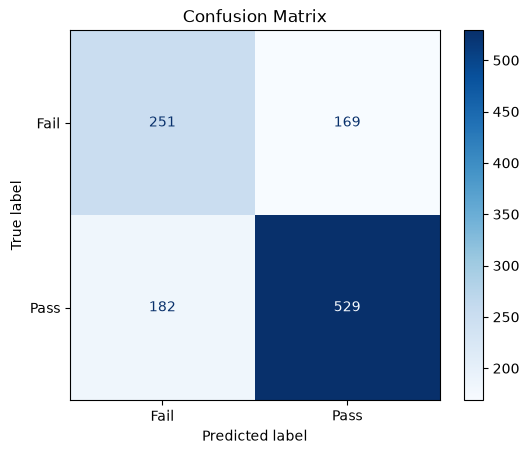

In [19]:
# Obtain out-of-fold estimates using five partitions
predictions = cross_val_predict(dt_clf, X, y, cv=5)

# Summarize the cross-validated class metrics
print(classification_report(y, predictions))

# Visualize the aggregated prediction errors
confusion_m = confusion_matrix(y, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_m, display_labels=["Fail", "Pass"])
disp.plot(cmap=plt.cm.Blues)

# Render the diagnostic chart
plt.title('Confusion Matrix')
plt.show()


              precision    recall  f1-score   support

        Fail       0.61      0.64      0.62       420
        Pass       0.78      0.75      0.77       711

    accuracy                           0.71      1131
   macro avg       0.69      0.70      0.69      1131
weighted avg       0.72      0.71      0.71      1131



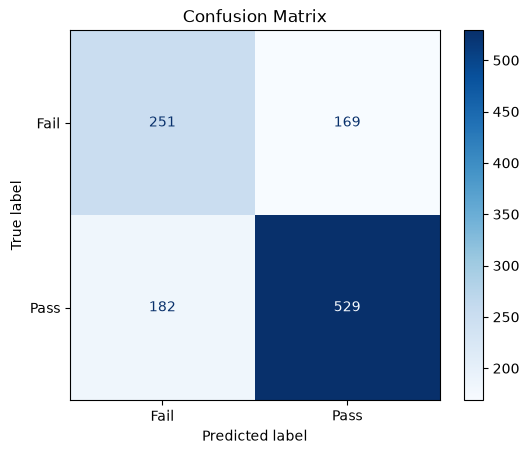

In [20]:

confusion_m = confusion_matrix(y, predictions)

# Calculate fresh predictions with ten validation folds
predictions = cross_val_predict(dt_clf, X, y, cv=10)

print(classification_report(y, predictions))

# Plot the matrix currently stored in confusion_m
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_m, display_labels=["Fail", "Pass"])
disp.plot(cmap=plt.cm.Blues)

# Render the chart
plt.title('Confusion Matrix')
plt.show()



KNN Cross-Validation Accuracy Scores: [0.81132075 0.76582278 0.75316456 0.7721519  0.77848101]
Mean Accuracy for KNN: 0.7761882015763077
SVM Cross-Validation Accuracy Scores: [0.67295597 0.66455696 0.68987342 0.67721519 0.6835443 ]
Mean Accuracy for SVM: 0.6776291696520979

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.65      0.68       294
           1       0.80      0.85      0.83       497

    accuracy                           0.78       791
   macro avg       0.76      0.75      0.76       791
weighted avg       0.77      0.78      0.77       791

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.40      0.48       294
           1       0.70      0.84      0.77       497

    accuracy                           0.68       791
   macro avg       0.65      0.62      0.62       791
weighted avg       0.66      0.68      0.66       791

KNN Confusion Mat

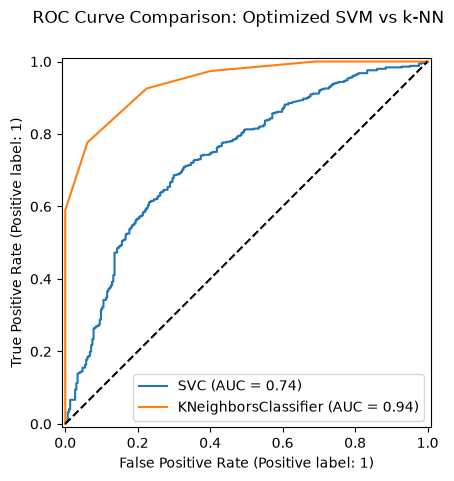

In [21]:
# Load the model-selection, plotting, and metric utilities
from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, RocCurveDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# A. Encode the outcome and prepare feature inputs
# ------------------------------------------------------------

# Convert the response into the numerical class convention
# Numerical labels are used by the ROC display utility
le = LabelEncoder()
student['Pass'] = le.fit_transform(student['Pass'])

# Define the predictors and response vector
X = student.drop('Pass', axis=1)  # All columns other than the response variable
y = student['Pass']  # Numerical response vector

# Create a fresh hold-out partition for these comparisons
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardize predictors for distance-based and margin-based models
# Fit the transform on training data and apply it to the test set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# B. Evaluate the candidate estimators by cross-validation
# ------------------------------------------------------------

# Instantiate the two estimators
knn_model = KNeighborsClassifier(n_neighbors=5)  # Five-neighbour configuration
svm_model = SVC(kernel='linear', C=1, probability=True, random_state=42)  # Linear SVM using the earlier selected penalty value

# Obtain five-fold accuracy measurements
knn_scores = cross_val_score(knn_model, X_train_scaled, y_train, cv=5, scoring='accuracy')
svm_scores = cross_val_score(svm_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

# Present the fold-wise and mean scores
print("KNN Cross-Validation Accuracy Scores:", knn_scores)
print("Mean Accuracy for KNN:", knn_scores.mean())
print("SVM Cross-Validation Accuracy Scores:", svm_scores)
print("Mean Accuracy for SVM:", svm_scores.mean())

# Derive out-of-fold labels for detailed assessment
knn_predictions = cross_val_predict(knn_model, X_train_scaled, y_train, cv=5)
svm_predictions = cross_val_predict(svm_model, X_train_scaled, y_train, cv=5)

# Report precision, recall, and F1 for both candidates
print("\nKNN Classification Report:")
print(classification_report(y_train, knn_predictions))

print("SVM Classification Report:")
print(classification_report(y_train, svm_predictions))

# Inspect each model’s confusion counts
print("KNN Confusion Matrix:")
print(confusion_matrix(y_train, knn_predictions))

print("SVM Confusion Matrix:")
print(confusion_matrix(y_train, svm_predictions))

# ------------------------------------------------------------
# C. Compare receiver operating characteristic curves
# ------------------------------------------------------------

# Refit each estimator using the whole training partition
# Use the previously selected linear-kernel SVM settings
svm_final = SVC(kernel='linear', C=1, probability=True, random_state=42)
svm_final.fit(X_train_scaled, y_train)

knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_scaled, y_train)

# Draw the SVM receiver operating characteristic
svm_disp = RocCurveDisplay.from_estimator(
    svm_final, 
    X_train_scaled, 
    y_train
)

# Overlay the nearest-neighbour ROC on the same axes
knn_disp = RocCurveDisplay.from_estimator(
    knn_final, 
    X_train_scaled, 
    y_train,
    ax=svm_disp.ax_
)

knn_disp.figure_.suptitle("ROC Curve Comparison: Optimized SVM vs k-NN")
plt.plot([0, 1], [0, 1], 'k--')
plt.show()

## Model comparison and interpretation


The original analysis favored **k-NN** over the evaluated **SVM** because its predictions appeared more balanced across `Pass` and `Fail`, even when overall accuracy was similar. In contrast, the SVM evaluation highlighted limited sensitivity to `Fail` cases.

These conclusions should be checked against the classification reports and ROC curves generated when the notebook is rerun. A useful model should be assessed on both overall discrimination and its ability to identify each class.
